Compare different models' performance in a summary table by aggregating evaluation metrics (accuracy, F1-score, ROC-AUC, training time), ranking models based on performance trade-offs, and visualizing comparisons through heatmaps or radar charts.

In [1]:
import joblib
import os
import shap
import numpy as np

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
save_folder = "task31_saved_files"

saved_models = "saved_models"
preprocessor = joblib.load(os.path.join(save_folder, "preprocessor.pkl"))
feature_config = joblib.load(os.path.join(save_folder, "feature_config.pkl"))
x_test = joblib.load(os.path.join(save_folder, "x_test.pkl"))
y_test = joblib.load(os.path.join(save_folder, "y_test.pkl"))
x_train = joblib.load(os.path.join(save_folder, "x_train.pkl"))
y_train = joblib.load(os.path.join(save_folder, "y_train.pkl"))

x_train_processed = preprocessor.transform(x_train)
x_test_processed = preprocessor.transform(x_test)

baseline_xgb_model = joblib.load(os.path.join(saved_models, "baseline_xgb_model.pkl"))

tuned_xgb_model = joblib.load(os.path.join(saved_models, "tuned_xgb_model.pkl"))

print("All saved files loaded successfully!")

All saved files loaded successfully!


In [3]:
import numpy as np
import pandas as pd

print("Training Data Shape:", x_train_processed.shape)
print("Testing Data Shape:", x_test_processed.shape)

print("\nData Type:", type(x_train_processed))

print("\nTraining Data Sparse:",hasattr(x_train_processed, "toarray"))

feature_names = preprocessor.get_feature_names_out()

print("\nNumber of Features:", len(feature_names))

print("\nTarget Distribution:")
print(pd.Series(y_train).value_counts())

print("\nTest Target Distribution:")
print(pd.Series(y_test).value_counts())

Training Data Shape: (18786, 3049)
Testing Data Shape: (4697, 3049)

Data Type: <class 'scipy.sparse._csr.csr_matrix'>

Training Data Sparse: True

Number of Features: 3049

Target Distribution:
recommend_flag
1    15448
0     3338
Name: count, dtype: int64

Test Target Distribution:
recommend_flag
1    3863
0     834
Name: count, dtype: int64


In [7]:

from scipy.sparse import issparse

for name, value in list(globals().items()):
    try:
        if issparse(value):
            print(f"{name}: {value.shape} | Sparse Matrix")
        elif isinstance(value, pd.DataFrame) and value.shape[1] > 100:
            print(f"{name}: {value.shape} | DataFrame")
    except Exception:
        pass


x_train_processed: (18786, 3049) | Sparse Matrix
x_test_processed: (4697, 3049) | Sparse Matrix


In [9]:

import time
from sklearn.feature_selection import RFE
from sklearn.svm import LinearSVC

rfe_start = time.time()

rfe_selector = RFE(
    estimator=LinearSVC(
        C=0.01,
        dual="auto",
        max_iter=5000,
        random_state=42
    ),
    n_features_to_select=100,
    step=0.1,
    verbose=1
)

# Feature selection
x_train_rfe = rfe_selector.fit_transform(
    x_train_processed, y_train
)

x_test_rfe = rfe_selector.transform(
    x_test_processed
)

rfe_feature_selection_time = time.time() - rfe_start

print("\nRFE FEATURE SELECTION COMPLETED")
print("-" * 40)
print("Original Features:", x_train_processed.shape[1])
print("Selected Features:", x_train_rfe.shape[1])
print("Training Shape:", x_train_rfe.shape)
print("Testing Shape:", x_test_rfe.shape)
print("Feature Selection Time:",
      round(rfe_feature_selection_time, 2), "seconds")


Fitting estimator with 3049 features.
Fitting estimator with 2745 features.
Fitting estimator with 2441 features.
Fitting estimator with 2137 features.
Fitting estimator with 1833 features.
Fitting estimator with 1529 features.
Fitting estimator with 1225 features.
Fitting estimator with 921 features.
Fitting estimator with 617 features.
Fitting estimator with 313 features.

RFE FEATURE SELECTION COMPLETED
----------------------------------------
Original Features: 3049
Selected Features: 100
Training Shape: (18786, 100)
Testing Shape: (4697, 100)
Feature Selection Time: 2.47 seconds


Train RFE + XGBoost

In [10]:
import time
from xgboost import XGBClassifier

In [11]:
rfe_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

rfe_xgb_start = time.time()

rfe_xgb_model.fit(x_train_rfe, y_train)

rfe_xgb_training_time = time.time() - rfe_xgb_start

print("RFE + XGBoost Training Completed!")
print("Training Time:",
      round(rfe_xgb_training_time, 2), "seconds")

RFE + XGBoost Training Completed!
Training Time: 0.74 seconds


Evaluate RFE + XGBoost

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

In [14]:
rfe_y_pred = rfe_xgb_model.predict(x_test_rfe)
rfe_y_prob = rfe_xgb_model.predict_proba(x_test_rfe)[:, 1]

# Evaluation metrics
rfe_accuracy = accuracy_score(y_test, rfe_y_pred)
rfe_precision = precision_score(y_test, rfe_y_pred)
rfe_recall = recall_score(y_test, rfe_y_pred)
rfe_f1 = f1_score(y_test, rfe_y_pred)
rfe_roc_auc = roc_auc_score(y_test, rfe_y_prob)

print("RFE + XGBoost PERFORMANCE")
print("-" * 40)
print(f"Accuracy:  {rfe_accuracy:.4f}")
print(f"Precision: {rfe_precision:.4f}")
print(f"Recall:    {rfe_recall:.4f}")
print(f"F1-Score:  {rfe_f1:.4f}")
print(f"ROC-AUC:   {rfe_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, rfe_y_pred))

RFE + XGBoost PERFORMANCE
----------------------------------------
Accuracy:  0.9442
Precision: 0.9700
Recall:    0.9619
F1-Score:  0.9659
ROC-AUC:   0.9804

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       834
           1       0.97      0.96      0.97      3863

    accuracy                           0.94      4697
   macro avg       0.90      0.91      0.91      4697
weighted avg       0.95      0.94      0.94      4697



Permutation Importance + XGBoost

In [17]:

import time
import numpy as np

from sklearn.metrics import roc_auc_score

pi_start = time.time()

# Baseline ROC-AUC
baseline_prob = temp_model.predict_proba(x_val)[:, 1]
baseline_auc = roc_auc_score(y_val, baseline_prob)

# Calculate importance by shuffling one feature at a time
pi_importances = np.zeros(x_val.shape[1])

rng = np.random.RandomState(42)

for feature_idx in range(x_val.shape[1]):

    X_shuffled = x_val.copy().tolil()

    shuffled_values = np.asarray(
        x_val[:, feature_idx].toarray()
    ).ravel()

    rng.shuffle(shuffled_values)

    X_shuffled[:, feature_idx] = shuffled_values
    X_shuffled = X_shuffled.tocsr()

    shuffled_prob = temp_model.predict_proba(X_shuffled)[:, 1]

    shuffled_auc = roc_auc_score(y_val, shuffled_prob)

    pi_importances[feature_idx] = baseline_auc - shuffled_auc

# Select top 100 features
top_100_indices = np.argsort(pi_importances)[-100:]

top_100_indices = top_100_indices[
    np.argsort(pi_importances[top_100_indices])[::-1]
]

# Transform training and testing data
x_train_pi = x_train_processed[:, top_100_indices]
x_test_pi = x_test_processed[:, top_100_indices]

pi_feature_selection_time = time.time() - pi_start

print("PERMUTATION IMPORTANCE COMPLETED")
print("-" * 45)
print("Baseline ROC-AUC:", round(baseline_auc, 4))
print("Original Features:", x_train_processed.shape[1])
print("Selected Features:", x_train_pi.shape[1])
print("Training Shape:", x_train_pi.shape)
print("Testing Shape:", x_test_pi.shape)
print("Feature Selection Time:",
      round(pi_feature_selection_time, 2), "seconds")

print("\nTop 20 Feature Importances:")
for idx in top_100_indices[:20]:
    print(f"Feature {idx}: {pi_importances[idx]:.6f}")


PERMUTATION IMPORTANCE COMPLETED
---------------------------------------------
Baseline ROC-AUC: 0.9804
Original Features: 3049
Selected Features: 100
Training Shape: (18786, 100)
Testing Shape: (4697, 100)
Feature Selection Time: 148.74 seconds

Top 20 Feature Importances:
Feature 1: 0.338310
Feature 2: 0.000524
Feature 4: 0.000521
Feature 596: 0.000432
Feature 6: 0.000391
Feature 2899: 0.000265
Feature 2890: 0.000258
Feature 774: 0.000210
Feature 1430: 0.000195
Feature 2678: 0.000189
Feature 0: 0.000170
Feature 1370: 0.000169
Feature 855: 0.000165
Feature 447: 0.000155
Feature 2063: 0.000151
Feature 503: 0.000149
Feature 2140: 0.000148
Feature 1462: 0.000145
Feature 2579: 0.000134
Feature 396: 0.000131


Train XGBoost on selected features

In [18]:
pi_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Training time
pi_training_start = time.time()

pi_xgb_model.fit(x_train_pi, y_train)

pi_training_time = time.time() - pi_training_start

print("Model Training Completed!")
print(f"Training Time: {pi_training_time:.2f} seconds")

Model Training Completed!
Training Time: 1.11 seconds


In [19]:
pi_y_pred = pi_xgb_model.predict(x_test_pi)
pi_y_prob = pi_xgb_model.predict_proba(x_test_pi)[:, 1]

pi_accuracy = accuracy_score(y_test, pi_y_pred)
pi_precision = precision_score(y_test, pi_y_pred)
pi_recall = recall_score(y_test, pi_y_pred)
pi_f1 = f1_score(y_test, pi_y_pred)
pi_roc_auc = roc_auc_score(y_test, pi_y_prob)

print("\nPERMUTATION IMPORTANCE + XGBOOST")
print("--------------------------------")
print(f"Accuracy:  {pi_accuracy:.4f}")
print(f"Precision: {pi_precision:.4f}")
print(f"Recall:    {pi_recall:.4f}")
print(f"F1-Score:  {pi_f1:.4f}")
print(f"ROC-AUC:   {pi_roc_auc:.4f}")
print(f"Training Time: {pi_training_time:.2f} seconds")


PERMUTATION IMPORTANCE + XGBOOST
--------------------------------
Accuracy:  0.9412
Precision: 0.9696
Recall:    0.9586
F1-Score:  0.9641
ROC-AUC:   0.9789
Training Time: 1.11 seconds


Permutation Importance reduced the original 3,049 features to 100 important features. The resulting XGBoost model achieved 94.12% accuracy, 96.41% F1-score and 97.89% ROC-AUC. It performed well, although RFE achieved slightly better results with much lower feature-selection time.

TruncatedSVD + XGBoost

In [20]:
from sklearn.decomposition import TruncatedSVD

svd_start = time.time()

svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

x_train_svd = svd.fit_transform(x_train_processed)
x_test_svd = svd.transform(x_test_processed)

svd_feature_selection_time = time.time() - svd_start

print("TRUNCATED SVD COMPLETED")
print("-----------------------")
print("Original Features:", x_train_processed.shape[1])
print("Reduced Features:", x_train_svd.shape[1])
print("Training Shape:", x_train_svd.shape)
print("Testing Shape:", x_test_svd.shape)

print(f"Feature Reduction Time: {svd_feature_selection_time:.2f} seconds")
print(f"Explained Variance Ratio: {svd.explained_variance_ratio_.sum():.4f}")

TRUNCATED SVD COMPLETED
-----------------------
Original Features: 3049
Reduced Features: 100
Training Shape: (18786, 100)
Testing Shape: (4697, 100)
Feature Reduction Time: 2.11 seconds
Explained Variance Ratio: 0.9453


Train XGBoost on TruncatedSVD data

In [21]:
svd_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

svd_training_start = time.time()

svd_xgb_model.fit(x_train_svd, y_train)

svd_training_time = time.time() - svd_training_start

print("TruncatedSVD + XGBoost Training Completed!")
print(f"Training Time: {svd_training_time:.2f} seconds")

TruncatedSVD + XGBoost Training Completed!
Training Time: 1.33 seconds


In [22]:


svd_y_pred = svd_xgb_model.predict(x_test_svd)
svd_y_prob = svd_xgb_model.predict_proba(x_test_svd)[:, 1]

svd_accuracy = accuracy_score(y_test, svd_y_pred)
svd_precision = precision_score(y_test, svd_y_pred)
svd_recall = recall_score(y_test, svd_y_pred)
svd_f1 = f1_score(y_test, svd_y_pred)
svd_roc_auc = roc_auc_score(y_test, svd_y_prob)

print("\nTRUNCATED SVD + XGBOOST")
print("-----------------------")
print(f"Accuracy:  {svd_accuracy:.4f}")
print(f"Precision: {svd_precision:.4f}")
print(f"Recall:    {svd_recall:.4f}")
print(f"F1-Score:  {svd_f1:.4f}")
print(f"ROC-AUC:   {svd_roc_auc:.4f}")
print(f"Training Time: {svd_training_time:.2f} seconds")


TRUNCATED SVD + XGBOOST
-----------------------
Accuracy:  0.9397
Precision: 0.9659
Recall:    0.9607
F1-Score:  0.9633
ROC-AUC:   0.9775
Training Time: 1.33 seconds


Final comparison table and ranking

In [23]:

comparison = pd.DataFrame({
    "Model": [
        "RFE + XGBoost",
        "Permutation + XGBoost",
        "TruncatedSVD + XGBoost"
    ],
    "Accuracy": [rfe_accuracy, pi_accuracy, svd_accuracy],
    "Precision": [rfe_precision, pi_precision, svd_precision],
    "Recall": [rfe_recall, pi_recall, svd_recall],
    "F1_Score": [rfe_f1, pi_f1, svd_f1],
    "ROC_AUC": [rfe_roc_auc, pi_roc_auc, svd_roc_auc],
    "Feature_Selection_Time": [
        rfe_feature_selection_time,
        pi_feature_selection_time,
        svd_feature_selection_time
    ],
    "Training_Time": [
        rfe_xgb_training_time,
        pi_training_time,
        svd_training_time
    ]
})

comparison["Measured_Total_Time"] = (
    comparison["Feature_Selection_Time"] +
    comparison["Training_Time"]
)

# Rank: higher predictive metrics are better
for col in ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]:
    comparison[col + "_Rank"] = comparison[col].rank(
        ascending=False, method="min"
    )

# Lower measured time is better
comparison["Time_Rank"] = comparison["Measured_Total_Time"].rank(
    ascending=True, method="min"
)

rank_columns = [
    "Accuracy_Rank", "Precision_Rank", "Recall_Rank",
    "F1_Score_Rank", "ROC_AUC_Rank", "Time_Rank"
]

comparison["Average_Rank"] = comparison[rank_columns].mean(axis=1)

comparison["Overall_Rank"] = comparison["Average_Rank"].rank(
    ascending=True, method="min"
).astype(int)

comparison = comparison.sort_values("Overall_Rank")

print("FINAL MODEL COMPARISON")
display(comparison.round(4))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Feature_Selection_Time,Training_Time,Measured_Total_Time,Accuracy_Rank,Precision_Rank,Recall_Rank,F1_Score_Rank,ROC_AUC_Rank,Time_Rank,Average_Rank,Overall_Rank
0,RFE + XGBoost,0.9442,0.9700,0.9619,0.9659,0.9804,2.4710,0.7422,3.2132,1.0,1.0,1.0,1.0,1.0,1.0,1.0000,1
1,Permutation + XGBoost,0.9412,0.9696,0.9586,0.9641,0.9789,148.7398,1.1053,149.8451,2.0,2.0,3.0,2.0,2.0,3.0,2.3333,2
2,TruncatedSVD + XGBoost,0.9397,0.9659,0.9607,0.9633,0.9775,2.1093,1.3289,3.4382,3.0,3.0,2.0,3.0,3.0,2.0,2.6667,3


Heatmap and Radar chart

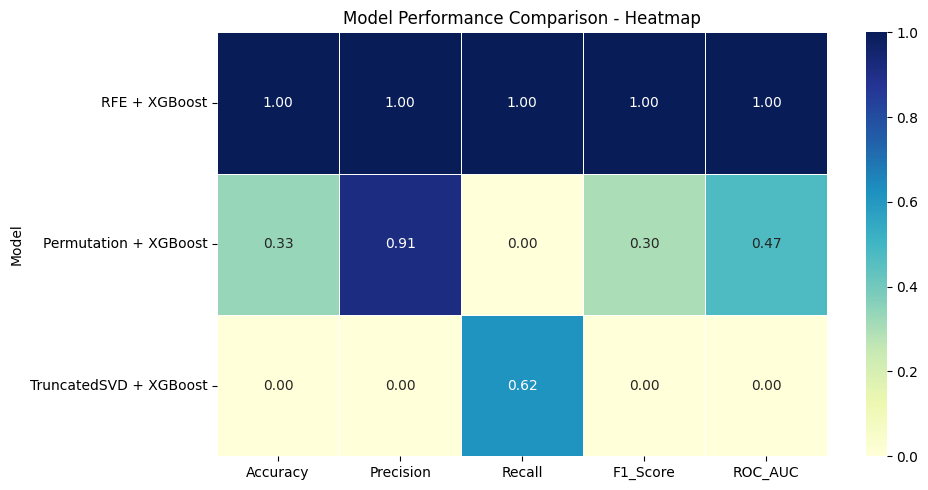

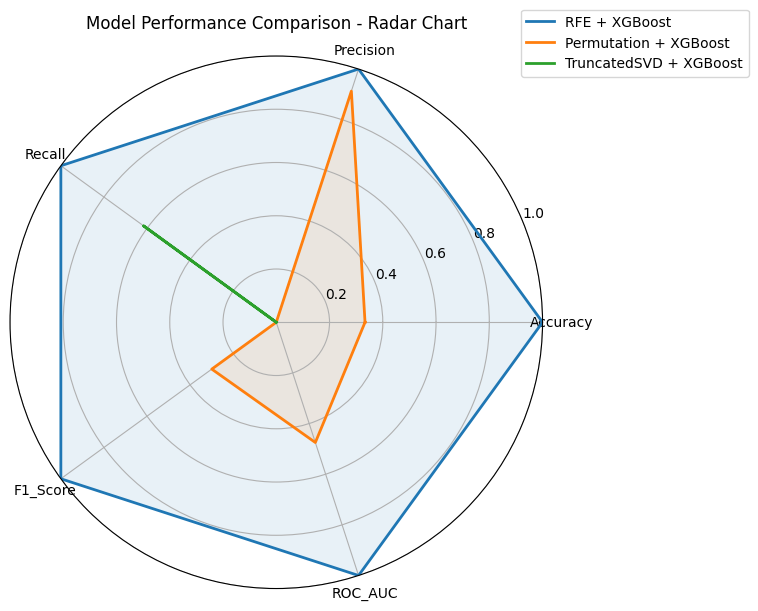

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Metrics for comparison
metric_columns = [
    "Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"
]

# Normalize metrics between 0 and 1
normalized = comparison.set_index("Model")[metric_columns].copy()

normalized = (
    normalized - normalized.min()
) / (
    normalized.max() - normalized.min()
)

# Heatmap
plt.figure(figsize=(10, 5))

sns.heatmap(
    normalized,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Model Performance Comparison - Heatmap")
plt.tight_layout()
plt.show()


# Radar Chart
radar_data = normalized.copy()

categories = metric_columns
angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
angles += angles[:1]

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

for model in radar_data.index:
    values = radar_data.loc[model].tolist()
    values += values[:1]

    ax.plot(angles, values, linewidth=2, label=model)
    ax.fill(angles, values, alpha=0.10)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)

ax.set_ylim(0, 1)
plt.title("Model Performance Comparison - Radar Chart", pad=20)
plt.legend(loc="upper right", bbox_to_anchor=(1.4, 1.1))
plt.tight_layout()
plt.show()

### Model Performance Comparison and Evaluation

Three feature-selection and dimensionality-reduction techniques—Recursive Feature Elimination (RFE), Permutation Importance, and Truncated Singular Value Decomposition (TruncatedSVD)—were evaluated using XGBoost.

All three models achieved strong predictive performance.

- **RFE + XGBoost:** Achieved the best results, with 94.42% accuracy, 96.59% F1-score and 98.04% ROC-AUC. It also required only 2.47 seconds for feature selection.
- **Permutation Importance + XGBoost:** Achieved 94.12% accuracy, 96.41% F1-score and 97.89% ROC-AUC. However, feature selection required 148.74 seconds.
- **TruncatedSVD + XGBoost:** Achieved 93.97% accuracy, 96.33% F1-score and 97.75% ROC-AUC. It reduced 3,049 original features to 100 components while retaining 94.53% explained variance.

The models were ranked using accuracy, precision, recall, F1-score, ROC-AUC and measured execution time. RFE + XGBoost achieved the first overall rank, followed by Permutation Importance + XGBoost and TruncatedSVD + XGBoost.

**Conclusion:** RFE + XGBoost provided the best balance of predictive performance and computational efficiency in this experiment. Therefore, it is the preferred model among the three evaluated approaches.